# EDA | Tortilla de maíz, salario mínimo y consumo de los hogares

## 1 | Pregunta y decisiones

**¿Cuánto pesa la tortilla de maíz en el salario mínimo y cómo ha cambiado entre 2014 y 2025?**

Se combinan tres fuentes públicas:

| Fuente | Qué aporta |
| --- | --- |
| CONASAMI | Salario mínimo diario vigente, por área salarial. |
| PROFECO (Quién es Quién en los Precios) | Precio de la tortilla en establecimientos, MXN/kg. |
| INEGI (ENIGH) | Consumo y gasto de tortilla de los hogares, años pares 2014–2024. |

Decisiones de análisis:

- **Ventana:** hasta diciembre de 2025. Las vigencias de 2026 del salario y los tres meses de 2026 de PROFECO se excluyen.
- **Precios:** solo tortilla de maíz de `1 Kg. Granel`, en tortillerías y autoservicio. Los precios son corrientes (sin deflactar).
- **Cobertura parcial de PROFECO:** cada año solo tiene entre 3 y 10 meses. Para comparar años se usa el promedio de **enero a marzo**, meses presentes en todos los años.
- **Peso de la tortilla:** se expresa de dos formas: kilogramos que compra un día de salario mínimo y gasto diario del hogar como porcentaje del salario mínimo diario.
- **Anomalías:** se detectan sobre registros individuales con dos técnicas y se contrastan con el comportamiento del mismo establecimiento.

## 2 | Fuentes y cobertura

In [1]:
# Importamos herramientas y fijamos una presentación común.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

AZUL, OCRE, GRIS, VERDE, ROJO = "#1f4e79", "#c27c0e", "#7f8c8d", "#2e7d5b", "#a93226"
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed" / "precio_tortilla_mensual.csv").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abre la libreta dentro del repositorio con los datos procesados.")
FIG = raiz / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG / f"tortilla_eda_{nombre}.png", dpi=150, bbox_inches="tight")

H = {}  # cifras que se reutilizan en la síntesis
ENTIDADES = {
    "01": "Aguascalientes", "02": "Baja California", "03": "Baja California Sur", "04": "Campeche",
    "05": "Coahuila", "06": "Colima", "07": "Chiapas", "08": "Chihuahua", "09": "Ciudad de México",
    "10": "Durango", "11": "Guanajuato", "12": "Guerrero", "13": "Hidalgo", "14": "Jalisco",
    "15": "Estado de México", "16": "Michoacán", "17": "Morelos", "18": "Nayarit", "19": "Nuevo León",
    "20": "Oaxaca", "21": "Puebla", "22": "Querétaro", "23": "Quintana Roo", "24": "San Luis Potosí",
    "25": "Sinaloa", "26": "Sonora", "27": "Tabasco", "28": "Tamaulipas", "29": "Tlaxcala",
    "30": "Veracruz", "31": "Yucatán", "32": "Zacatecas",
}

In [2]:
# Cargamos las tablas procesadas y las intermedias.
LIMITE = pd.Timestamp("2025-12-01")
sal_todo = pd.read_csv(raiz / "data/processed/salario_minimo_mensual.csv", parse_dates=["fecha"])
pre_todo = pd.read_csv(raiz / "data/processed/precio_tortilla_mensual.csv", parse_dates=["fecha"])
eni = pd.read_csv(raiz / "data/processed/enigh_tortilla_hogar.csv", dtype={"clave_nivel": str})
qqp = pd.read_parquet(raiz / "data/interim/PROFECO/qqp_tortilla_maiz.parquet")
hog = pd.concat(
    [pd.read_parquet(f).assign(anio=int(f.stem[-4:]))
     for f in sorted((raiz / "data/interim/ENIGH").glob("tortilla_hogar_*.parquet"))],
    ignore_index=True,
)

sal = sal_todo[sal_todo["fecha"] <= LIMITE].copy()
pre = pre_todo[pre_todo["fecha"] <= LIMITE].copy()
pre["anio"], pre["mes"] = pre["fecha"].dt.year, pre["fecha"].dt.month

assert not sal.duplicated(["fecha", "area"]).any()
assert not pre.duplicated(["fecha", "nivel", "estado", "giro"]).any()
assert not eni.duplicated(["anio", "nivel", "clave_nivel"]).any()
assert (sal["salario_minimo_diario_mxn"] > 0).all() and pre["precio_mediana_mxn_kg"].between(5, 60).all()

### 2.1 | Cobertura por fuente

In [3]:
nac = pre[(pre["nivel"] == "nacional") & (pre["giro"] == "tortilleria")]
cobertura = pd.DataFrame([
    ["CONASAMI (salario mínimo)", "Mensual", sal["fecha"].min().strftime("%Y-%m"), sal["fecha"].max().strftime("%Y-%m"),
     sal["fecha"].nunique(), 156, len(sal), "Área salarial", "MXN/día"],
    ["PROFECO (precio de tortilla)", "Mensual", nac["fecha"].min().strftime("%Y-%m"), nac["fecha"].max().strftime("%Y-%m"),
     nac["fecha"].nunique(), 132, len(pre), "Nacional/estado y giro", "MXN/kg"],
    ["ENIGH (consumo del hogar)", "Bienal", str(eni["anio"].min()), str(eni["anio"].max()),
     eni["anio"].nunique(), 6, len(eni), "Nacional/entidad/decil", "kg/día, MXN/día"],
], columns=["fuente", "frecuencia", "inicio", "fin", "periodos con dato", "periodos esperados", "filas", "desagregación", "unidad"])
display(cobertura)
print(f"Registros individuales de precio (todos los giros y presentaciones): {len(qqp):,}")
print(f"Hogares ENIGH en las tablas intermedias (2014–2024): {len(hog):,}")

,fuente,frecuencia,inicio,fin,periodos con dato,periodos esperados,filas,desagregación,unidad
0,CONASAMI (salario mínimo),Mensual,2013-01,2025-12,156,156,240,Área salarial,MXN/día
1,PROFECO (precio de tortilla),Mensual,2015-01,2025-07,85,132,5151,Nacional/estado y giro,MXN/kg
2,ENIGH (consumo del hogar),Bienal,2014,2024,6,6,258,Nacional/entidad/decil,"kg/día, MXN/día"


Registros individuales de precio (todos los giros y presentaciones): 350,307
Hogares ENIGH en las tablas intermedias (2014–2024): 434,959


### 2.2 | Meses faltantes de PROFECO

La fuente publica solo el primer volumen de cada año. Cada celda muestra el número de registros nacionales de tortillería; las celdas grises no tienen dato.

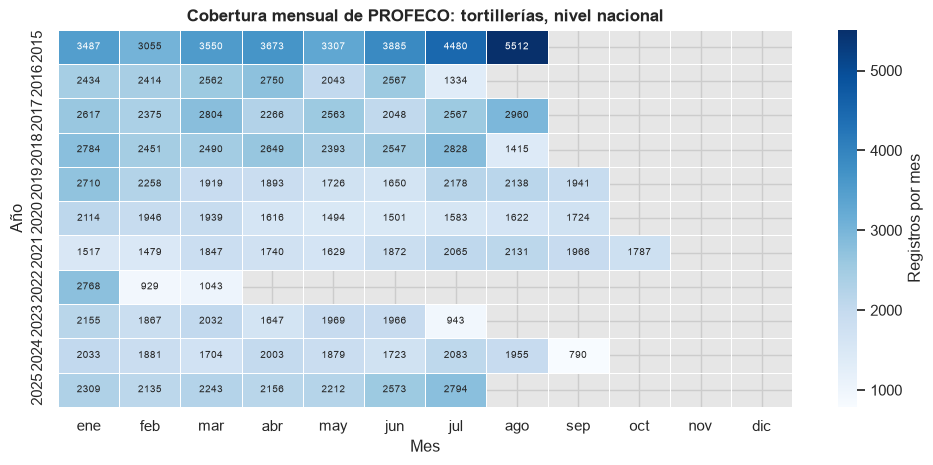

Hay entre **3 y 10 meses por año** (85 de 132 posibles). Todos los años tienen enero–marzo; ningún año tiene noviembre ni diciembre.

In [4]:
mapa = (nac.pivot_table(index="anio", columns="mes", values="n_registros")
        .reindex(index=range(2015, 2026), columns=range(1, 13)))
meses_anio = mapa.notna().sum(axis=1)
H["meses_min"], H["meses_max"] = int(meses_anio.min()), int(meses_anio.max())
H["meses_total"] = int(meses_anio.sum())

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(mapa, annot=True, fmt=".0f", annot_kws={"size": 7}, cmap="Blues", linewidths=0.5,
            linecolor="white", cbar_kws={"label": "Registros por mes"}, ax=ax)
ax.set_facecolor("#e6e6e6")
ax.set_title("Cobertura mensual de PROFECO: tortillerías, nivel nacional")
ax.set_xlabel("Mes"); ax.set_ylabel("Año")
ax.set_xticklabels(["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"], rotation=0)
plt.tight_layout(); guardar(fig, "cobertura_profeco"); plt.show()
display(Markdown(
    f"Hay entre **{H['meses_min']} y {H['meses_max']} meses por año** ({H['meses_total']} de 132 posibles). "
    f"Todos los años tienen enero–marzo; ningún año tiene noviembre ni diciembre."
))

## 3 | Salario mínimo

### 3.1 | Escalones y crecimiento nominal

El salario cambia una vez al año (con ajustes extraordinarios en 2015 y 2017). La Zona Libre de la Frontera Norte (ZLFN) existe desde 2019.

In [5]:
sal["anio"] = sal["fecha"].dt.year
vig = sal.sort_values(["area", "fecha"]).copy()
vig["anterior"] = vig.groupby("area")["salario_minimo_diario_mxn"].shift()
vig = vig[vig["salario_minimo_diario_mxn"].ne(vig["anterior"]) & vig["anterior"].notna()].copy()
vig["incremento_pct"] = (vig["salario_minimo_diario_mxn"] / vig["anterior"] - 1) * 100
display(vig.assign(fecha=vig["fecha"].dt.strftime("%Y-%m"))
        [["fecha", "area", "anterior", "salario_minimo_diario_mxn", "incremento_pct"]]
        .rename(columns={"anterior": "salario_previo_mxn", "salario_minimo_diario_mxn": "salario_nuevo_mxn"})
        .round(1).reset_index(drop=True))

,fecha,area,salario_previo_mxn,salario_nuevo_mxn,incremento_pct
0,2014-01,general,61.4,63.8,3.9
1,2015-01,general,63.8,66.4,4.2
2,2015-04,general,66.4,68.3,2.8
3,2015-10,general,68.3,70.1,2.7
4,2016-01,general,70.1,73.0,4.2
5,2017-01,general,73.0,80.0,9.6
6,2017-12,general,80.0,88.4,10.4
7,2019-01,general,88.4,102.7,16.2
8,2020-01,general,102.7,123.2,20.0
9,2021-01,general,123.2,141.7,15.0


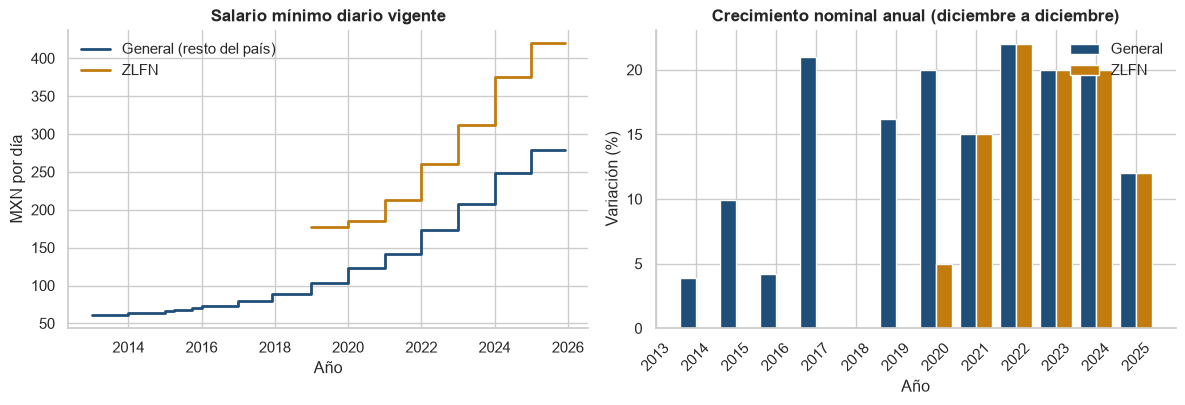

anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
area,,,,,,,,,,,,,
general_%,NaN,3.9,9.9,4.2,21.0,0.0,16.2,20.0,15.0,22.0,20.0,20.0,12.0
zlfn_%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,22.0,20.0,20.0,12.0


In [6]:
dic = (sal[sal["fecha"].dt.month == 12]
       .pivot(index="anio", columns="area", values="salario_minimo_diario_mxn"))
crec = dic.pct_change() * 100
crec.loc[dic["zlfn"].isna() | dic["zlfn"].shift().isna(), "zlfn"] = np.nan

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for area, color, nombre in [("general", AZUL, "General (resto del país)"), ("zlfn", OCRE, "ZLFN")]:
    s = sal[sal["area"] == area].set_index("fecha")["salario_minimo_diario_mxn"]
    axs[0].step(s.index, s.values, where="post", color=color, lw=2, label=nombre)
axs[0].set_title("Salario mínimo diario vigente"); axs[0].set_ylabel("MXN por día"); axs[0].set_xlabel("Año")
axs[0].legend(frameon=False)

x = np.arange(len(crec))
axs[1].bar(x - 0.2, crec["general"], 0.4, color=AZUL, label="General")
axs[1].bar(x + 0.2, crec["zlfn"], 0.4, color=OCRE, label="ZLFN")
axs[1].set_xticks(x); axs[1].set_xticklabels(crec.index, rotation=45)
axs[1].set_title("Crecimiento nominal anual (diciembre a diciembre)")
axs[1].set_ylabel("Variación (%)"); axs[1].set_xlabel("Año"); axs[1].legend(frameon=False)
plt.tight_layout(); guardar(fig, "salario_minimo"); plt.show()
display(crec.round(1).rename(columns={"general": "general_%", "zlfn": "zlfn_%"}).T)

In [7]:
g13 = sal.loc[(sal["area"] == "general") & (sal["fecha"] == "2013-01-01"), "salario_minimo_diario_mxn"].iat[0]
g25 = dic.loc[2025, "general"]
z19, z25 = dic.loc[2019, "zlfn"], dic.loc[2025, "zlfn"]
H.update(g13=g13, g25=g25, g_factor=g25 / g13, g_cagr=((g25 / g13) ** (1 / 12.92) - 1) * 100,
         g_antes19=dic.loc[2018, "general"], g_2019=dic.loc[2019, "general"],
         z19=z19, z25=z25, brecha25=(z25 / g25 - 1) * 100, brecha19=(z19 / dic.loc[2019, "general"] - 1) * 100,
         g_cre_2019=crec.loc[2019, "general"], g_cre_med_20_25=crec.loc[2020:2025, "general"].mean())
display(Markdown(
    f"- El salario general pasó de **{g13:.2f}** MXN/día (ene 2013) a **{g25:.2f}** (dic 2025): "
    f"**{H['g_factor']:.1f} veces** el nivel inicial, {H['g_cagr']:.1f} % anual compuesto.\n"
    f"- El crecimiento se concentra desde 2019: {H['g_cre_2019']:.1f} % en 2019 y {H['g_cre_med_20_25']:.1f} % promedio anual en 2020–2025.\n"
    f"- La ZLFN pasó de {z19:.2f} a {z25:.2f} MXN/día entre 2019 y 2025; su ventaja sobre el general "
    f"bajó de {H['brecha19']:.0f} % a {H['brecha25']:.0f} %."
))

- El salario general pasó de **61.38** MXN/día (ene 2013) a **278.80** (dic 2025): **4.5 veces** el nivel inicial, 12.4 % anual compuesto.
- El crecimiento se concentra desde 2019: 16.2 % en 2019 y 18.2 % promedio anual en 2020–2025.
- La ZLFN pasó de 176.72 a 419.88 MXN/día entre 2019 y 2025; su ventaja sobre el general bajó de 72 % a 51 %.

## 4 | Precio de la tortilla

### 4.1 | Serie nacional: tortillería y autoservicio

El nivel nacional es la mediana de las medianas estatales. Los huecos en la línea son meses sin dato.

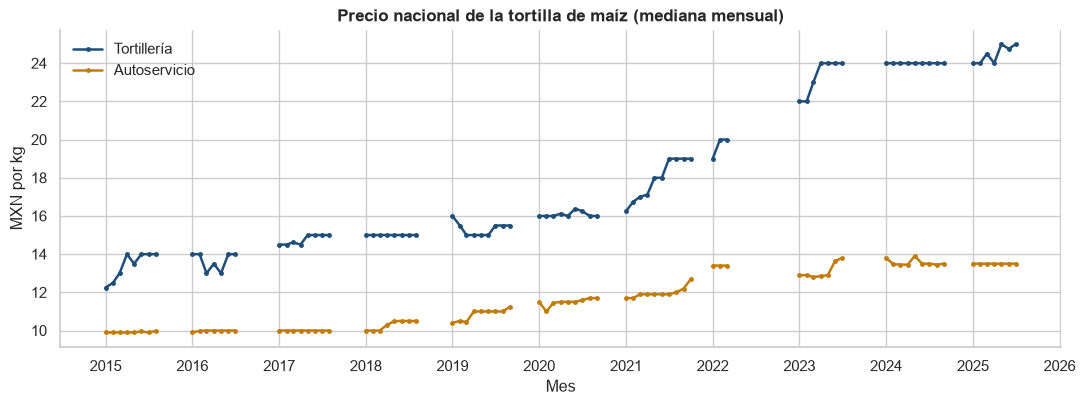

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
giro,,,,,,,,,,,
autoservicio,9.90,9.96,10.00,10.00,10.45,11.31,11.77,13.40,12.87,13.58,13.50
tortilleria,12.58,13.67,14.54,15.00,15.50,16.00,16.67,19.67,22.33,24.00,24.17
autoservicio/tortilleria,0.79,0.73,0.69,0.67,0.67,0.71,0.71,0.68,0.58,0.57,0.56


In [8]:
idx = pd.date_range("2015-01-01", "2025-12-01", freq="MS")
ser = (pre[pre["nivel"] == "nacional"].pivot(index="fecha", columns="giro", values="precio_mediana_mxn_kg")
       .reindex(idx))
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(ser.index, ser["tortilleria"], color=AZUL, lw=1.8, marker="o", ms=2.5, label="Tortillería")
ax.plot(ser.index, ser["autoservicio"], color=OCRE, lw=1.8, marker="o", ms=2.5, label="Autoservicio")
ax.set_title("Precio nacional de la tortilla de maíz (mediana mensual)")
ax.set_ylabel("MXN por kg"); ax.set_xlabel("Mes")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(frameon=False)
plt.tight_layout(); guardar(fig, "precio_nacional"); plt.show()

q1 = (pre[(pre["nivel"] == "nacional") & (pre["mes"] <= 3)]
      .groupby(["anio", "giro"])["precio_mediana_mxn_kg"].mean().unstack())
q1["autoservicio/tortilleria"] = q1["autoservicio"] / q1["tortilleria"]
display(q1.round(2).T)

In [9]:
t15, t25 = q1.loc[2015, "tortilleria"], q1.loc[2025, "tortilleria"]
a15, a25 = q1.loc[2015, "autoservicio"], q1.loc[2025, "autoservicio"]
H.update(t15=t15, t25=t25, t_var=(t25 / t15 - 1) * 100, a15=a15, a25=a25, a_var=(a25 / a15 - 1) * 100,
         t_cagr=((t25 / t15) ** (1 / 10) - 1) * 100,
         razon_min=q1["autoservicio/tortilleria"].min(), razon_max=q1["autoservicio/tortilleria"].max())
display(Markdown(
    f"- Promedio ene–mar de la tortillería: **{t15:.2f}** MXN/kg en 2015 y **{t25:.2f}** en 2025 "
    f"(+{H['t_var']:.0f} %, {H['t_cagr']:.1f} % anual).\n"
    f"- Autoservicio: {a15:.2f} a {a25:.2f} MXN/kg (+{H['a_var']:.0f} %). Su precio equivale a "
    f"{H['razon_min']*100:.0f}–{H['razon_max']*100:.0f} % del de tortillería según el año."
))

- Promedio ene–mar de la tortillería: **12.58** MXN/kg en 2015 y **24.17** en 2025 (+92 %, 6.7 % anual).
- Autoservicio: 9.90 a 13.50 MXN/kg (+36 %). Su precio equivale a 56–79 % del de tortillería según el año.

### 4.2 | Dispersión entre estados

Cada punto de la caja es la mediana mensual de un estado (tortillería, enero–marzo).

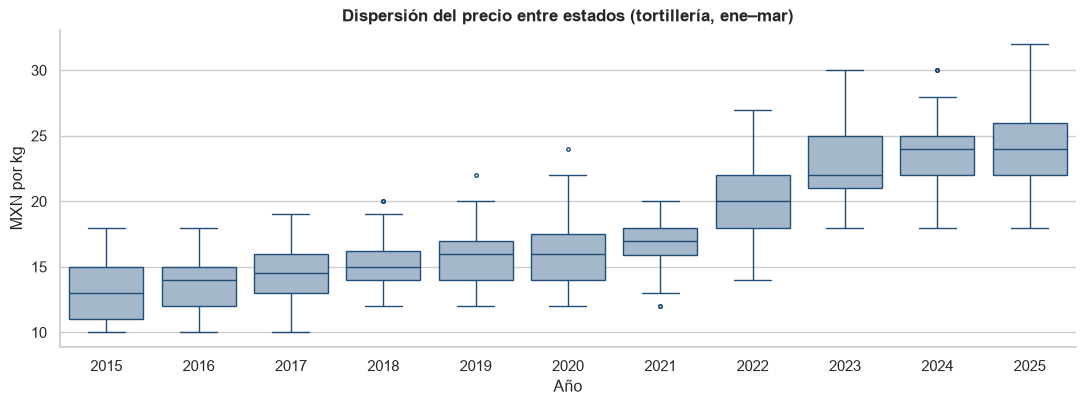

,p10,mediana,p90,minimo,maximo,razon_p90_p10,cv_%
anio,,,,,,,
2015,10.0,13.0,15.00,10.0,18.0,1.50,16.73
2016,11.1,14.0,16.00,10.0,18.0,1.44,13.79
2017,12.0,14.5,17.00,10.0,19.0,1.42,12.78
2018,12.5,15.0,17.00,12.0,20.0,1.36,12.81
2019,14.0,16.0,18.00,12.0,22.0,1.29,12.44
2020,14.0,16.0,18.00,12.0,24.0,1.29,14.17
2021,14.0,17.0,19.25,12.0,20.0,1.38,11.71
2022,17.0,20.0,23.00,14.0,27.0,1.35,13.88
2023,20.0,22.0,27.00,18.0,30.0,1.35,12.34


La dispersión relativa entre estados pasa de **16.7 %** (2015) a **12.3 %** (2025) y la razón p90/p10 de 1.50 a 1.33; en pesos, la amplitud entre extremos va de 8 a 14 MXN/kg.

In [10]:
est = pre[(pre["nivel"] == "estado") & (pre["giro"] == "tortilleria")]
est_q1 = est[est["mes"] <= 3]
disp = est_q1.groupby("anio")["precio_mediana_mxn_kg"].agg(
    p10=lambda s: s.quantile(.1), mediana="median", p90=lambda s: s.quantile(.9), minimo="min", maximo="max")
disp["razon_p90_p10"] = disp["p90"] / disp["p10"]
cv = est_q1.groupby("anio")["precio_mediana_mxn_kg"].agg(lambda s: s.std() / s.mean() * 100).rename("cv_%")
disp = disp.join(cv)

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=est_q1, x="anio", y="precio_mediana_mxn_kg", color="#9db7d1", linecolor=AZUL,
            fliersize=2.5, ax=ax)
ax.set_title("Dispersión del precio entre estados (tortillería, ene–mar)")
ax.set_xlabel("Año"); ax.set_ylabel("MXN por kg")
plt.tight_layout(); guardar(fig, "dispersion_estados"); plt.show()
display(disp.round(2))
H.update(cv15=disp.loc[2015, "cv_%"], cv25=disp.loc[2025, "cv_%"], r15=disp.loc[2015, "razon_p90_p10"], r25=disp.loc[2025, "razon_p90_p10"],
         amp15=disp.loc[2015, "maximo"] - disp.loc[2015, "minimo"], amp25=disp.loc[2025, "maximo"] - disp.loc[2025, "minimo"])
display(Markdown(
    f"La dispersión relativa entre estados pasa de **{H['cv15']:.1f} %** (2015) a **{H['cv25']:.1f} %** (2025) y la razón p90/p10 de {H['r15']:.2f} a {H['r25']:.2f}; "
    f"en pesos, la amplitud entre extremos va de {H['amp15']:.0f} a {H['amp25']:.0f} MXN/kg."
))

### 4.3 | Estado por año y estados más caros y baratos

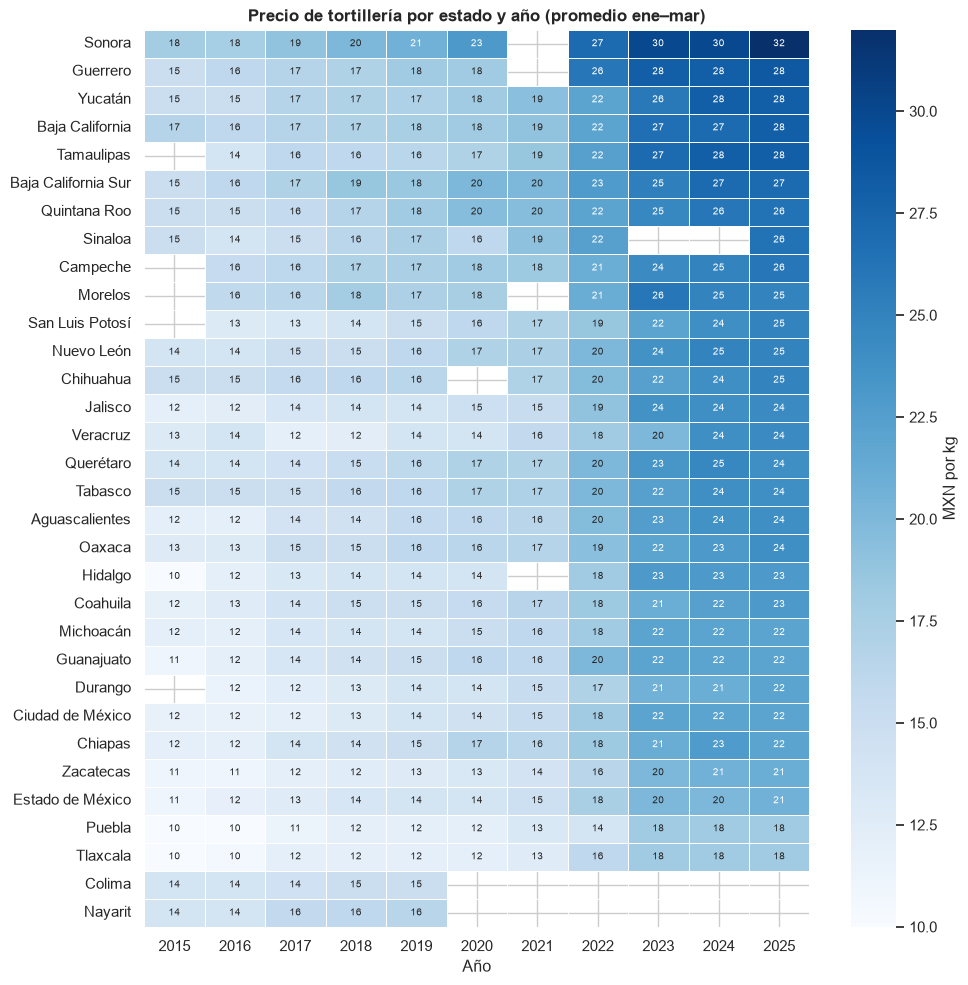

Celdas estado-año sin dato: 24


In [11]:
mat = est_q1.groupby(["estado", "anio"])["precio_mediana_mxn_kg"].mean().unstack()
mat = mat.loc[mat[2025].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(mat, annot=True, fmt=".0f", annot_kws={"size": 7}, cmap="Blues", linewidths=0.4,
            linecolor="white", cbar_kws={"label": "MXN por kg"}, ax=ax)
ax.set_title("Precio de tortillería por estado y año (promedio ene–mar)")
ax.set_xlabel("Año"); ax.set_ylabel("")
plt.tight_layout(); guardar(fig, "mapa_calor_estado_anio"); plt.show()
print(f"Celdas estado-año sin dato: {int(mat.isna().sum().sum())}")

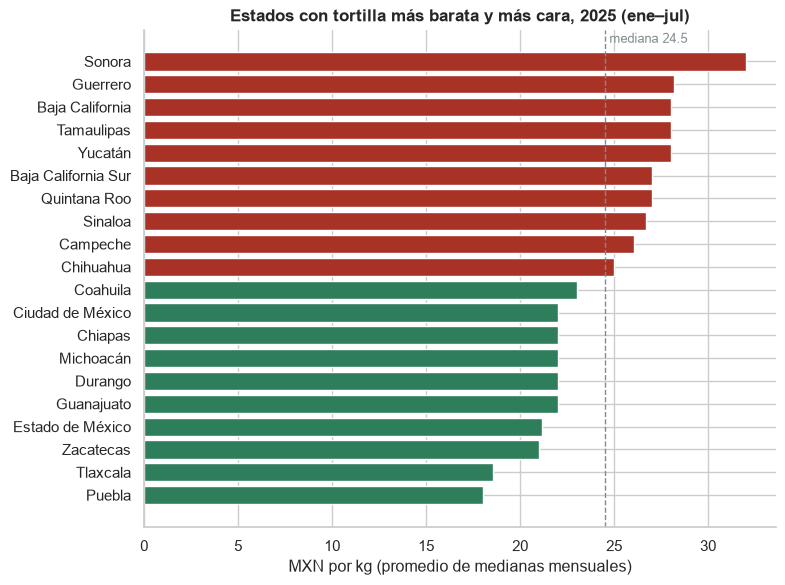

En 2025 (30 estados con al menos 4 meses) el más barato es **Puebla** (18.0 MXN/kg) y el más caro **Sonora** (32.0); la mediana entre estados es 24.5.

In [12]:
e25 = est[(est["anio"] == 2025)].groupby("estado")["precio_mediana_mxn_kg"].agg(["mean", "count"])
e25 = e25[e25["count"] >= 4]["mean"].sort_values()
extremos = pd.concat([e25.head(10), e25.tail(10)])
H.update(barato=e25.index[0], p_barato=e25.iloc[0], caro=e25.index[-1], p_caro=e25.iloc[-1],
         mediana25=e25.median(), n_est25=len(e25))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(extremos.index, extremos.values, color=[VERDE] * 10 + [ROJO] * 10)
ax.axvline(e25.median(), color=GRIS, ls="--", lw=1)
ax.text(e25.median(), 19.7, f" mediana {e25.median():.1f}", color=GRIS, va="bottom", fontsize=9)
ax.set_title("Estados con tortilla más barata y más cara, 2025 (ene–jul)")
ax.set_xlabel("MXN por kg (promedio de medianas mensuales)"); ax.set_ylabel("")
plt.tight_layout(); guardar(fig, "estados_extremos_2025"); plt.show()
display(Markdown(
    f"En 2025 ({H['n_est25']} estados con al menos 4 meses) el más barato es **{H['barato']}** ({H['p_barato']:.1f} MXN/kg) y el más caro "
    f"**{H['caro']}** ({H['p_caro']:.1f}); la mediana entre estados es {H['mediana25']:.1f}."
))

## 5 | Anomalías en precios individuales

Se trabaja con los registros de tortillería y autoservicio de `1 Kg. Granel`. Dentro de cada estado, mes y giro (mínimo 8 registros) se aplican dos técnicas:

- **IQR:** precio fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR].
- **Z-score robusto:** |0.6745·(x − mediana)/MAD| > 3.5; si MAD es cero, se usa IQR/1.349 como escala.

Luego se distingue entre captura errónea y precio alto real con dos pruebas: (a) magnitud respecto a la mediana del grupo y (b) si el mismo establecimiento reporta precios parecidos en su mes y los adyacentes.

In [13]:
reg = qqp[(qqp["presentacion"] == "1 Kg. Granel") & qqp["giro"].isin(["tortilleria", "autoservicio"])].copy()
reg = reg[reg["fecha"] <= "2025-12-31"].reset_index(drop=True)
reg["mes_p"] = reg["fecha"].dt.to_period("M")
g = reg.groupby(["estado", "mes_p", "giro"])["precio_mxn"]
reg["n_grupo"] = g.transform("size")
reg["mediana_g"] = g.transform("median")
q1_, q3_ = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
iqr = q3_ - q1_
reg["mad"] = (reg["precio_mxn"] - reg["mediana_g"]).abs().groupby([reg["estado"], reg["mes_p"], reg["giro"]]).transform("median")
escala = np.where(reg["mad"] > 0, reg["mad"] / 0.6745, iqr / 1.349)

apto = reg["n_grupo"] >= 8
reg["f_iqr"] = apto & ((reg["precio_mxn"] < q1_ - 1.5 * iqr) | (reg["precio_mxn"] > q3_ + 1.5 * iqr))
with np.errstate(divide="ignore", invalid="ignore"):
    reg["z_rob"] = np.where(escala > 0, (reg["precio_mxn"] - reg["mediana_g"]) / escala, np.nan)
reg["f_z"] = apto & (reg["z_rob"].abs() > 3.5)
reg["razon_mediana"] = reg["precio_mxn"] / reg["mediana_g"]

resumen = pd.DataFrame({
    "registros evaluados": [apto.sum()],
    "marcados por IQR": [reg["f_iqr"].sum()],
    "marcados por z robusto": [reg["f_z"].sum()],
    "ambas técnicas": [(reg["f_iqr"] & reg["f_z"]).sum()],
    "al menos una": [(reg["f_iqr"] | reg["f_z"]).sum()],
})
display(resumen)
H.update(n_eval=int(apto.sum()), n_iqr=int(reg["f_iqr"].sum()), n_z=int(reg["f_z"].sum()),
         n_ambas=int((reg["f_iqr"] & reg["f_z"]).sum()), n_alguna=int((reg["f_iqr"] | reg["f_z"]).sum()))
H["pct_medio_peso"] = (reg["precio_mxn"] * 2 % 1 == 0).mean() * 100
print(f"Precio mínimo y máximo observados: {reg['precio_mxn'].min():.1f} y {reg['precio_mxn'].max():.1f} MXN/kg")
print(f"Precios en pesos enteros o medios pesos: {H['pct_medio_peso']:.1f} %")

,registros evaluados,marcados por IQR,marcados por z robusto,ambas técnicas,al menos una
0,311380,21808,10559,7166,25201


Precio mínimo y máximo observados: 7.0 y 32.0 MXN/kg
Precios en pesos enteros o medios pesos: 80.6 %


### 5.1 | Contraste con el establecimiento

In [14]:
# Promedio de los demás registros del mismo establecimiento en el mes y los dos adyacentes.
reg["est"] = (reg["estado"].astype(str) + "|" + reg["cadena_comercial"].astype(str) + "|"
              + reg["nombre_comercial"].astype(str) + "|" + reg["direccion"].astype(str))
em = reg.groupby(["est", "mes_p"])["precio_mxn"].agg(["sum", "count"])
def vecino(d):
    s = em.copy()
    s.index = pd.MultiIndex.from_arrays([s.index.get_level_values(0), s.index.get_level_values(1) + d])
    return s
tot = em.add(vecino(1), fill_value=0).add(vecino(-1), fill_value=0)
llave = pd.MultiIndex.from_arrays([reg["est"], reg["mes_p"]])
suma, cuenta = tot["sum"].reindex(llave).to_numpy(), tot["count"].reindex(llave).to_numpy()
with np.errstate(divide="ignore", invalid="ignore"):
    reg["media_otros"] = np.where(cuenta > 1, (suma - reg["precio_mxn"]) / (cuenta - 1), np.nan)
reg["razon_est"] = reg["precio_mxn"] / reg["media_otros"]

marc = reg[reg["f_iqr"] | reg["f_z"]].copy()
conf = marc["razon_est"].between(0.9, 1.1)
extremo = (marc["razon_mediana"] >= 2) | (marc["razon_mediana"] <= 0.5)
aislado = marc["razon_est"].notna() & ((marc["razon_est"] >= 1.25) | (marc["razon_est"] <= 0.8))
marc["clase"] = np.select(
    [extremo | aislado, conf, marc["razon_est"].isna()],
    ["captura errónea probable", "atípico sostenido (establecimiento)", "sin contraste"],
    default="atípico sin confirmar",
)
marc["alto"] = marc["precio_mxn"] > marc["mediana_g"]
clases = marc.groupby("clase").agg(registros=("precio_mxn", "size"), pct=("precio_mxn", lambda s: len(s) / len(marc) * 100),
                                   pct_altos=("alto", lambda s: s.mean() * 100), razon_mediana=("razon_mediana", "median"))
display(clases.round(1))
H.update(n_error=int(clases.loc["captura errónea probable", "registros"]) if "captura errónea probable" in clases.index else 0,
         n_real=int(clases.loc["atípico sostenido (establecimiento)", "registros"]) if "atípico sostenido (establecimiento)" in clases.index else 0)

,registros,pct,pct_altos,razon_mediana
clase,,,,
atípico sin confirmar,798,3.2,69.7,1.1
atípico sostenido (establecimiento),24226,96.1,54.7,1.0
captura errónea probable,150,0.6,76.0,1.3
sin contraste,27,0.1,48.1,1.0


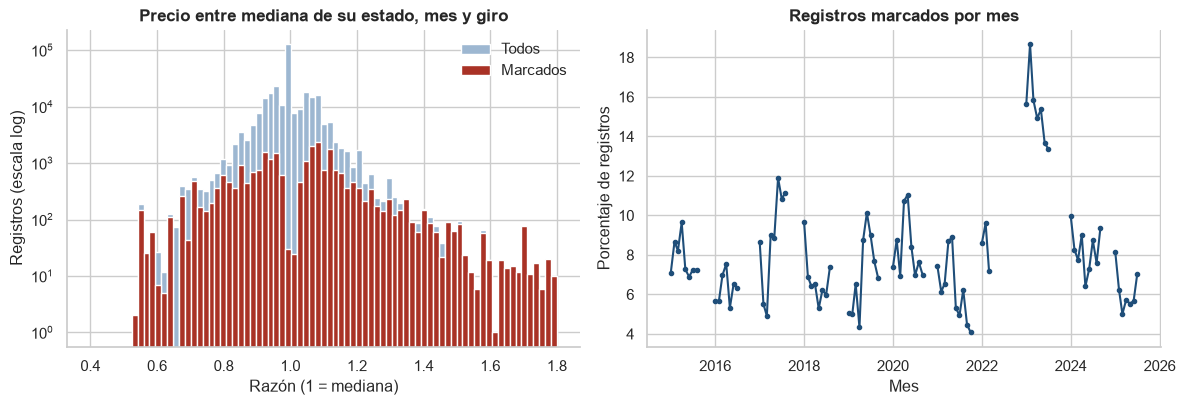

Se marcó el **8.1 %** de los registros (25,201); 7,166 por ambas técnicas. Solo 150 se clasifican como captura errónea probable; 24,226 son atípicos sostenidos: el mismo establecimiento cobra de forma consistente más o menos que su entorno. Como 81 % de los precios son pesos enteros o medios pesos, el rango intercuartil es estrecho y las reglas marcan diferencias de uno o dos pesos.

estado,Michoacán,Chiapas,San Luis Potosí,Baja California,Colima
"% de registros marcados, por estado",15.6,15.1,14.2,12.3,11.1


In [15]:
reg["clase"] = marc["clase"].reindex(reg.index)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].hist(reg["razon_mediana"], bins=np.linspace(0.4, 1.8, 80), color="#9db7d1", label="Todos")
axs[0].hist(marc["razon_mediana"], bins=np.linspace(0.4, 1.8, 80), color=ROJO, label="Marcados")
axs[0].set_yscale("log"); axs[0].legend(frameon=False)
axs[0].set_title("Precio entre mediana de su estado, mes y giro")
axs[0].set_xlabel("Razón (1 = mediana)"); axs[0].set_ylabel("Registros (escala log)")

por_mes = (reg.assign(marcado=reg["f_iqr"] | reg["f_z"]).groupby("mes_p")["marcado"].mean() * 100)
por_mes.index = por_mes.index.to_timestamp()
por_mes = por_mes.reindex(idx)
axs[1].plot(por_mes.index, por_mes.values, color=AZUL, marker="o", ms=3, lw=1.5)
axs[1].set_title("Registros marcados por mes"); axs[1].set_xlabel("Mes"); axs[1].set_ylabel("Porcentaje de registros")
plt.tight_layout(); guardar(fig, "anomalias"); plt.show()

H["pct_marc"] = H["n_alguna"] / len(reg) * 100
top = (marc.groupby("estado").size().div(reg.groupby("estado").size()).mul(100).sort_values(ascending=False).head(5))
display(Markdown(
    f"Se marcó el **{H['pct_marc']:.1f} %** de los registros ({H['n_alguna']:,}); {H['n_ambas']:,} por ambas técnicas. "
    f"Solo {H['n_error']:,} se clasifican como captura errónea probable; {H['n_real']:,} son atípicos sostenidos: el mismo establecimiento cobra de forma consistente más o menos que su entorno. "
    f"Como {H['pct_medio_peso']:.0f} % de los precios son pesos enteros o medios pesos, el rango intercuartil es estrecho y las reglas marcan diferencias de uno o dos pesos."
))
display(top.round(1).rename("% de registros marcados, por estado").to_frame().T)

### 5.2 | Alzas reales frente a cambios de muestra

Un salto de la mediana estatal es un alza real si lo respalda la mayoría de los establecimientos. Se compara cada establecimiento con su propio precio del mes anterior (alza: +5 % o más), en estado, giro y mes con al menos 8 establecimientos comunes.

In [16]:
pe = reg.groupby(["estado", "giro", "est", "mes_p"])["precio_mxn"].median().reset_index()
prev = pe.assign(mes_p=pe["mes_p"] + 1).rename(columns={"precio_mxn": "p_prev"})
pe = pe.merge(prev, on=["estado", "giro", "est", "mes_p"])
pe["sube"] = pe["precio_mxn"] / pe["p_prev"] - 1 >= 0.05
resp = pe.groupby(["estado", "giro", "mes_p"]).agg(pct_suben=("sube", lambda s: s.mean() * 100), n_comunes=("sube", "size")).reset_index()

med = reg.groupby(["estado", "giro", "mes_p"])["precio_mxn"].median().rename("med").reset_index()
med = med.merge(med.assign(mes_p=med["mes_p"] + 1).rename(columns={"med": "med_prev"}), on=["estado", "giro", "mes_p"])
med["salto_pct"] = (med["med"] / med["med_prev"] - 1) * 100
saltos = med.merge(resp, on=["estado", "giro", "mes_p"])
saltos = saltos[saltos["n_comunes"] >= 8].sort_values("salto_pct", ascending=False)
tabla = saltos.head(8).assign(mes=lambda d: d["mes_p"].astype(str))[["estado", "giro", "mes", "med_prev", "med", "salto_pct", "pct_suben", "n_comunes"]]
display(tabla.round(1).reset_index(drop=True))
g10 = saltos[saltos["salto_pct"] >= 10]
H.update(salto_max=saltos["salto_pct"].iloc[0], n_g10=len(g10),
         n_g10_resp=int((g10["pct_suben"] >= 50).sum()), n_g10_no=int((g10["pct_suben"] < 20).sum()))

,estado,giro,mes,med_prev,med,salto_pct,pct_suben,n_comunes
0,Puebla,tortilleria,2017-02,10.0,12.0,20.0,24.0,25
1,Quintana Roo,tortilleria,2020-08,17.0,20.0,17.6,0.0,25
2,Sinaloa,tortilleria,2016-06,12.8,15.0,17.6,0.0,17
3,Tlaxcala,tortilleria,2021-03,12.0,14.0,16.7,81.8,11
4,Hidalgo,tortilleria,2017-02,12.0,14.0,16.7,33.3,12
5,Baja California,tortilleria,2021-06,19.0,22.0,15.8,62.5,8
6,Sinaloa,tortilleria,2016-03,13.0,15.0,15.4,0.0,19
7,Veracruz,tortilleria,2020-05,14.0,16.0,14.3,0.0,10


In [17]:
display(Markdown(
    f"De **{H['n_g10']}** saltos mensuales de la mediana estatal de 10 % o más (máximo {H['salto_max']:.1f} %), "
    f"solo **{H['n_g10_resp']}** están respaldados por al menos la mitad de los establecimientos comunes; "
    f"en **{H['n_g10_no']}** menos del 20 % subió su precio. Esos saltos reflejan sobre todo cambios en los establecimientos levantados "
    f"y precios en escalones de pesos enteros."
))

De **26** saltos mensuales de la mediana estatal de 10 % o más (máximo 20.0 %), solo **9** están respaldados por al menos la mitad de los establecimientos comunes; en **10** menos del 20 % subió su precio. Esos saltos reflejan sobre todo cambios en los establecimientos levantados y precios en escalones de pesos enteros.

## 6 | Consumo de tortilla en los hogares (ENIGH)

Los promedios incluyen hogares sin compra. El consumo es compra monetaria; el gasto y los precios son corrientes.

### 6.1 | Nivel nacional

,kg_dia_hogar,kg_dia_per_capita,pct_hogares_compran,kg_dia_hogar_compradores,gasto_dia_hogar_mxn,precio_implicito_mxn_kg
anio,,,,,,
2014,0.543,0.144,80.64,0.674,6.432,11.836
2016,0.514,0.140,81.88,0.628,6.457,12.564
2018,0.514,0.143,82.53,0.623,7.365,14.334
2020,0.525,0.148,83.52,0.628,8.124,15.481
2022,0.485,0.141,83.44,0.582,10.328,21.283
2024,0.455,0.136,83.22,0.546,10.303,22.663


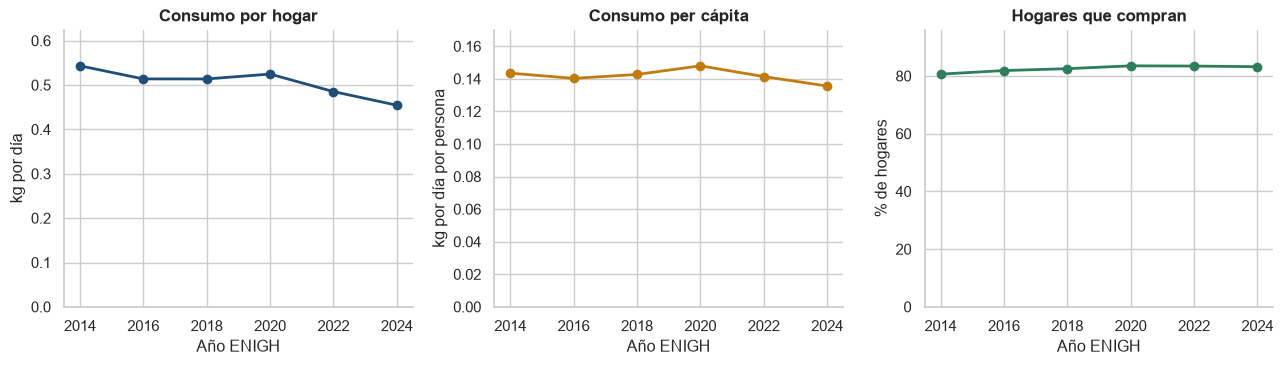

- Consumo por hogar: **0.543 → 0.455** kg/día (-16 %); máximo en 2014.
- Per cápita: 0.143 → 0.136 kg/día (-6 %). La caída es menor porque los hogares son más pequeños (de 3.79 a 3.35 integrantes, según el cociente entre ambas medidas).
- Hogares que compran: 80.6 % → 83.2 %. Entre compradores: 0.67 → 0.55 kg/día.

In [18]:
nac_e = eni[eni["nivel"] == "nacional"].set_index("anio")
cols = ["kg_dia_hogar", "kg_dia_per_capita", "pct_hogares_compran", "kg_dia_hogar_compradores", "gasto_dia_hogar_mxn", "precio_implicito_mxn_kg"]
display(nac_e[cols].round(3))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, tit, uni, color in [
    (axs[0], "kg_dia_hogar", "Consumo por hogar", "kg por día", AZUL),
    (axs[1], "kg_dia_per_capita", "Consumo per cápita", "kg por día por persona", OCRE),
    (axs[2], "pct_hogares_compran", "Hogares que compran", "% de hogares", VERDE)]:
    ax.plot(nac_e.index, nac_e[col], marker="o", color=color, lw=2)
    ax.set_title(tit); ax.set_ylabel(uni); ax.set_xlabel("Año ENIGH"); ax.set_xticks(nac_e.index)
    ax.set_ylim(0, nac_e[col].max() * 1.15)
plt.tight_layout(); guardar(fig, "enigh_nacional"); plt.show()

a, b = nac_e.loc[2014], nac_e.loc[2024]
H.update(kg14=a["kg_dia_hogar"], kg24=b["kg_dia_hogar"], kg_var=(b["kg_dia_hogar"] / a["kg_dia_hogar"] - 1) * 100,
         pc14=a["kg_dia_per_capita"], pc24=b["kg_dia_per_capita"], pc_var=(b["kg_dia_per_capita"] / a["kg_dia_per_capita"] - 1) * 100,
         pct14=a["pct_hogares_compran"], pct24=b["pct_hogares_compran"],
         comp14=a["kg_dia_hogar_compradores"], comp24=b["kg_dia_hogar_compradores"],
         kg_max_anio=int(nac_e["kg_dia_hogar"].idxmax()),
         tam14=a["kg_dia_hogar"] / a["kg_dia_per_capita"], tam24=b["kg_dia_hogar"] / b["kg_dia_per_capita"])
display(Markdown(
    f"- Consumo por hogar: **{H['kg14']:.3f} → {H['kg24']:.3f}** kg/día ({H['kg_var']:+.0f} %); máximo en {H['kg_max_anio']}.\n"
    f"- Per cápita: {H['pc14']:.3f} → {H['pc24']:.3f} kg/día ({H['pc_var']:+.0f} %). La caída es menor porque los hogares son más pequeños (de {H['tam14']:.2f} a {H['tam24']:.2f} integrantes, según el cociente entre ambas medidas).\n"
    f"- Hogares que compran: {H['pct14']:.1f} % → {H['pct24']:.1f} %. Entre compradores: {H['comp14']:.2f} → {H['comp24']:.2f} kg/día."
))

### 6.2 | Por decil de ingreso

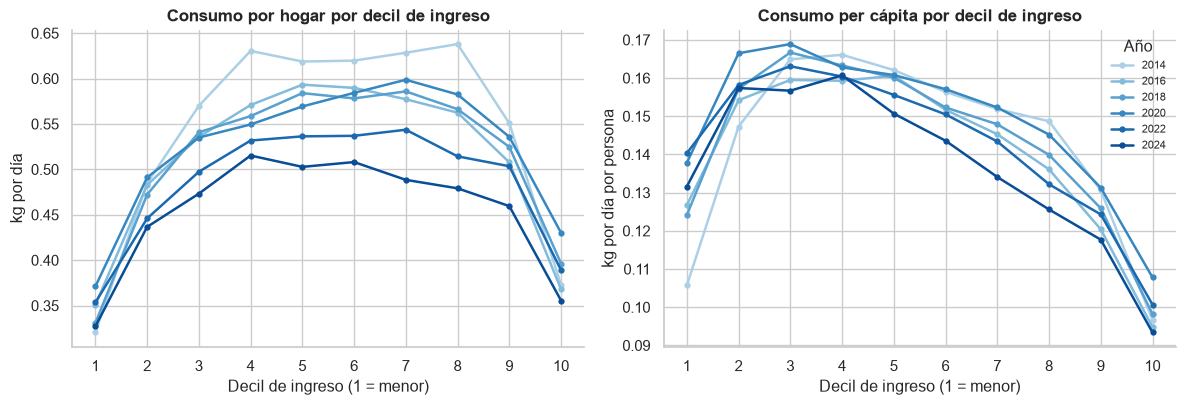

decil,1,2,3,4,5,6,7,8,9,10
2014,0.320,0.485,0.570,0.630,0.619,0.620,0.628,0.638,0.551,0.373
2016,0.351,0.483,0.536,0.571,0.593,0.590,0.577,0.562,0.508,0.368
2018,0.331,0.472,0.541,0.559,0.584,0.578,0.586,0.566,0.525,0.396
2020,0.371,0.491,0.535,0.550,0.569,0.584,0.599,0.582,0.536,0.430
2022,0.354,0.446,0.497,0.532,0.536,0.537,0.544,0.514,0.503,0.389
2024,0.327,0.437,0.473,0.515,0.503,0.508,0.488,0.479,0.460,0.356
variación_2014_2024_%,2.000,-10.000,-17.000,-18.000,-19.000,-18.000,-22.000,-25.000,-17.000,-5.000


- El decil 1 pasa de 0.321 a 0.327 kg/día (+2 %) y el decil 10 de 0.373 a 0.356 (-5 %).
- La mayor caída está en el decil 8 (-25 %).

In [19]:
dec = eni[eni["nivel"] == "decil"].assign(decil=lambda d: d["clave_nivel"].astype(int))
kg_dec = dec.pivot(index="decil", columns="anio", values="kg_dia_hogar")
pc_dec = dec.pivot(index="decil", columns="anio", values="kg_dia_per_capita")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
paleta = sns.color_palette("Blues", n_colors=len(kg_dec.columns) + 2)[2:]
for ax, tab, tit, uni in [(axs[0], kg_dec, "Consumo por hogar", "kg por día"), (axs[1], pc_dec, "Consumo per cápita", "kg por día por persona")]:
    for c, anio in zip(paleta, tab.columns):
        ax.plot(tab.index, tab[anio], marker="o", ms=3.5, color=c, label=str(anio), lw=1.8)
    ax.set_title(tit + " por decil de ingreso"); ax.set_xlabel("Decil de ingreso (1 = menor)"); ax.set_ylabel(uni)
    ax.set_xticks(range(1, 11))
axs[1].legend(title="Año", frameon=False, fontsize=8)
plt.tight_layout(); guardar(fig, "enigh_deciles"); plt.show()

var_dec = ((kg_dec[2024] / kg_dec[2014] - 1) * 100).rename("variación_2014_2024_%")
display(pd.concat([kg_dec.round(3), var_dec.round(0)], axis=1).T)
H.update(d1_14=kg_dec.loc[1, 2014], d1_24=kg_dec.loc[1, 2024], d10_14=kg_dec.loc[10, 2014], d10_24=kg_dec.loc[10, 2024],
         d1_var=var_dec.loc[1], d10_var=var_dec.loc[10],
         pc_d1_24=pc_dec.loc[1, 2024], pc_d10_24=pc_dec.loc[10, 2024],
         dec_cae=int(var_dec.idxmin()), dec_cae_v=var_dec.min())
display(Markdown(
    f"- El decil 1 pasa de {H['d1_14']:.3f} a {H['d1_24']:.3f} kg/día ({H['d1_var']:+.0f} %) y el decil 10 de {H['d10_14']:.3f} a {H['d10_24']:.3f} ({H['d10_var']:+.0f} %).\n"
    f"- La mayor caída está en el decil {H['dec_cae']} ({H['dec_cae_v']:.0f} %)."
))

### 6.3 | Por entidad

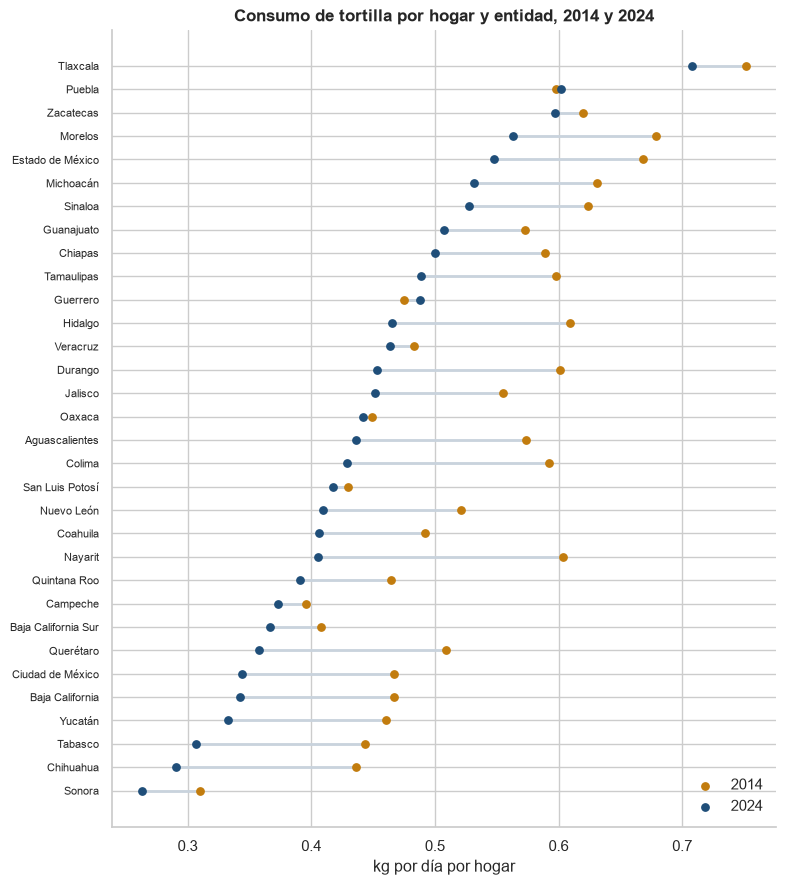

El consumo por hogar bajó en **30 de 32** entidades. La mayor caída es Chihuahua (-33 %); el cambio más favorable, Guerrero (+3 %). En 2024 el mayor consumo es de Tlaxcala (0.71 kg/día) y el menor de Sonora (0.26).

In [20]:
ent = eni[eni["nivel"] == "entidad"].assign(estado=lambda d: d["clave_nivel"].map(ENTIDADES))
assert ent["estado"].notna().all()
k = ent.pivot(index="estado", columns="anio", values="kg_dia_hogar")
k["var"] = (k[2024] / k[2014] - 1) * 100
k = k.sort_values(2024)

fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(k))
ax.hlines(y, k[2024], k[2014], color="#c9d3dd", lw=2)
ax.scatter(k[2014], y, color=OCRE, s=28, label="2014", zorder=3)
ax.scatter(k[2024], y, color=AZUL, s=28, label="2024", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(k.index, fontsize=8)
ax.set_title("Consumo de tortilla por hogar y entidad, 2014 y 2024")
ax.set_xlabel("kg por día por hogar"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); guardar(fig, "enigh_entidades"); plt.show()
H.update(ent_cae=int((k["var"] < 0).sum()), ent_n=len(k), ent_max=k["var"].idxmin(), ent_max_v=k["var"].min(),
         ent_min=k["var"].idxmax(), ent_min_v=k["var"].max(),
         ent_top=k.index[-1], ent_top_v=k[2024].iloc[-1], ent_bot=k.index[0], ent_bot_v=k[2024].iloc[0])
display(Markdown(
    f"El consumo por hogar bajó en **{H['ent_cae']} de {H['ent_n']}** entidades. La mayor caída es {H['ent_max']} ({H['ent_max_v']:.0f} %); "
    f"el cambio más favorable, {H['ent_min']} ({H['ent_min_v']:+.0f} %). En 2024 el mayor consumo es de {H['ent_top']} "
    f"({H['ent_top_v']:.2f} kg/día) y el menor de {H['ent_bot']} ({H['ent_bot_v']:.2f})."
))

## 7 | Consistencia entre fuentes

### 7.1 | Precio implícito ENIGH frente a la mediana PROFECO

El precio implícito de ENIGH es gasto entre cantidad declarados por los hogares. PROFECO es el precio observado en establecimientos. Se comparan los años comunes (2016–2024). ENIGH levanta en el segundo semestre del año; PROFECO solo tiene los primeros meses.

,enigh_implicito,enigh_mediana_hogar,profeco_tortilleria_ene_mar,profeco_tortilleria_ult_mes,profeco_autoservicio_ene_mar,meses_profeco,dif_vs_tortilleria_ult_mes_%,dif_vs_tortilleria_ene_mar_%
anio,,,,,,,,
2016,12.56,12.8,13.67,14.0,9.96,7,-10.26,-8.07
2018,14.33,14.6,15.00,15.0,10.00,8,-4.44,-4.44
2020,15.48,16.0,16.00,16.0,11.31,9,-3.24,-3.24
2022,21.28,22.0,19.67,20.0,13.40,3,6.41,8.22
2024,22.66,23.2,24.00,24.0,13.58,9,-5.57,-5.57


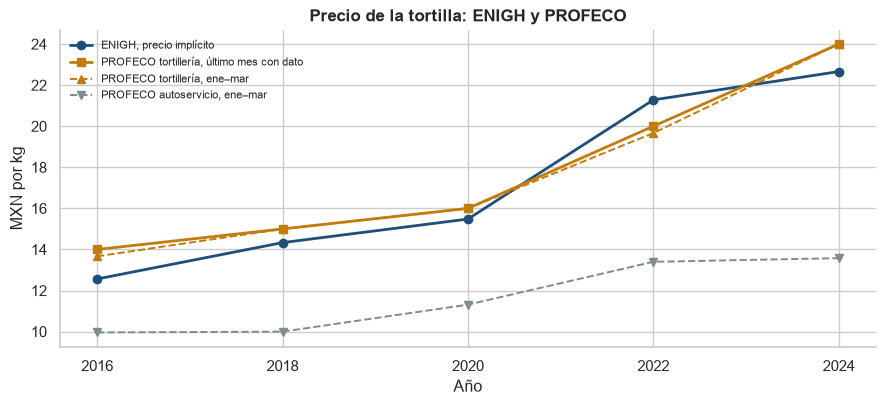

In [21]:
tor = pre[(pre["nivel"] == "nacional")]
p_q1 = tor[tor["mes"] <= 3].groupby(["anio", "giro"])["precio_mediana_mxn_kg"].mean().unstack()
p_all = tor.groupby(["anio", "giro"])["precio_mediana_mxn_kg"].mean().unstack()
p_last = tor.merge(tor.groupby(["anio", "giro"])["mes"].max().rename("ult").reset_index(), on=["anio", "giro"])
p_last = p_last[p_last["mes"] == p_last["ult"]].set_index(["anio", "giro"])["precio_mediana_mxn_kg"].unstack()

cmp_ = pd.DataFrame({
    "enigh_implicito": nac_e["precio_implicito_mxn_kg"],
    "enigh_mediana_hogar": nac_e["precio_mediano_hogar_mxn_kg"],
    "profeco_tortilleria_ene_mar": p_q1["tortilleria"],
    "profeco_tortilleria_ult_mes": p_last["tortilleria"],
    "profeco_autoservicio_ene_mar": p_q1["autoservicio"],
}).dropna()
cmp_["meses_profeco"] = tor[tor["giro"] == "tortilleria"].groupby("anio")["mes"].max().reindex(cmp_.index)
cmp_["dif_vs_tortilleria_ult_mes_%"] = (cmp_["enigh_implicito"] / cmp_["profeco_tortilleria_ult_mes"] - 1) * 100
cmp_["dif_vs_tortilleria_ene_mar_%"] = (cmp_["enigh_implicito"] / cmp_["profeco_tortilleria_ene_mar"] - 1) * 100
display(cmp_.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(cmp_.index, cmp_["enigh_implicito"], marker="o", color=AZUL, lw=2, label="ENIGH, precio implícito")
ax.plot(cmp_.index, cmp_["profeco_tortilleria_ult_mes"], marker="s", color=OCRE, lw=2, label="PROFECO tortillería, último mes con dato")
ax.plot(cmp_.index, cmp_["profeco_tortilleria_ene_mar"], marker="^", color=OCRE, lw=1.4, ls="--", label="PROFECO tortillería, ene–mar")
ax.plot(cmp_.index, cmp_["profeco_autoservicio_ene_mar"], marker="v", color=GRIS, lw=1.4, ls="--", label="PROFECO autoservicio, ene–mar")
ax.set_title("Precio de la tortilla: ENIGH y PROFECO"); ax.set_xlabel("Año"); ax.set_ylabel("MXN por kg"); ax.set_xticks(cmp_.index)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); guardar(fig, "consistencia_precio"); plt.show()

In [22]:
d_ult = cmp_["dif_vs_tortilleria_ult_mes_%"]
r_corr = cmp_["enigh_implicito"].corr(cmp_["profeco_tortilleria_ult_mes"])
H.update(dif_ult_min=d_ult.min(), dif_ult_max=d_ult.max(), dif_ult_med=d_ult.mean(), corr_nac=r_corr,
         dif_q1_med=cmp_["dif_vs_tortilleria_ene_mar_%"].mean(),
         dif_22=d_ult.loc[2022], meses22=int(cmp_.loc[2022, "meses_profeco"]))
display(Markdown(
    f"- Frente al último mes con dato de PROFECO, el precio implícito de ENIGH difiere entre **{H['dif_ult_min']:+.0f} % y {H['dif_ult_max']:+.0f} %** "
    f"(promedio {H['dif_ult_med']:+.0f} %); la correlación de niveles es {H['corr_nac']:.3f}.\n"
    f"- ENIGH queda por encima de PROFECO solo en {', '.join(str(a) for a in d_ult.index[d_ult > 0])} (año con {H['meses22']} meses de PROFECO); en los demás años queda por debajo."
))

- Frente al último mes con dato de PROFECO, el precio implícito de ENIGH difiere entre **-10 % y +6 %** (promedio -3 %); la correlación de niveles es 0.970.
- ENIGH queda por encima de PROFECO solo en 2022 (año con 3 meses de PROFECO); en los demás años queda por debajo.

### 7.2 | Precio por entidad y variabilidad entre hogares

Se comparan por entidad el precio implícito ENIGH y el promedio PROFECO de la tortillería en los meses disponibles del mismo año. Después se revisa la distribución del precio declarado por los hogares compradores.

anio,2016,2018,2020,2022,2024
correlación,0.83,0.83,0.87,0.82,0.87
razón mediana ENIGH/PROFECO,0.97,0.97,0.99,1.10,0.98


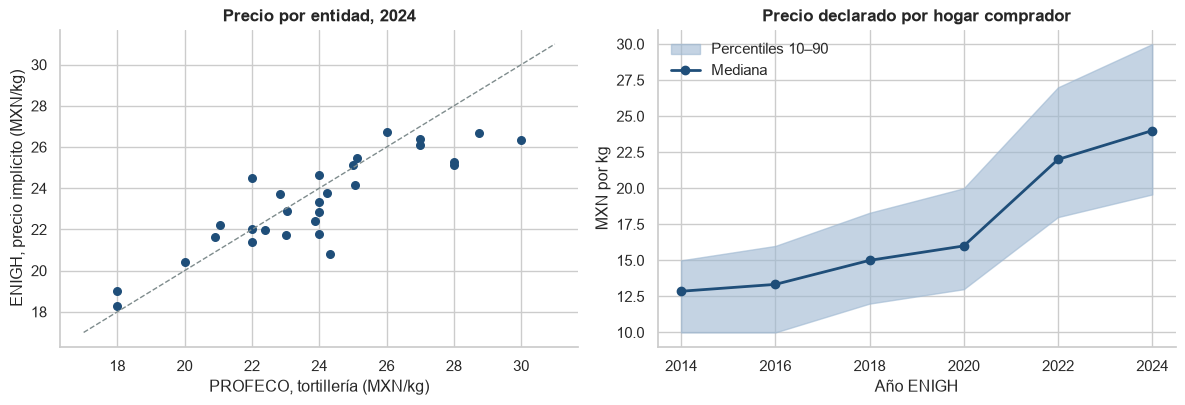

Entre entidades, la correlación ENIGH–PROFECO por año va de 0.82 a 0.87. En 2024 la mitad central de los hogares declara precios entre 20 y 30 MXN/kg (percentiles 10–90).

In [23]:
pe_est = (pre[(pre["nivel"] == "estado") & (pre["giro"] == "tortilleria")]
          .groupby(["estado", "anio"])["precio_mediana_mxn_kg"].mean().rename("profeco").reset_index())
ei = ent.rename(columns={"anio": "anio"})[["estado", "anio", "precio_implicito_mxn_kg"]].rename(columns={"precio_implicito_mxn_kg": "enigh"})
est_cmp = ei.merge(pe_est, on=["estado", "anio"])
est_cmp["razon"] = est_cmp["enigh"] / est_cmp["profeco"]
corr_anio = est_cmp.groupby("anio").apply(lambda d: d["enigh"].corr(d["profeco"]), include_groups=False).rename("correlación")
razon_anio = est_cmp.groupby("anio")["razon"].median().rename("razón mediana ENIGH/PROFECO")
display(pd.concat([corr_anio, razon_anio], axis=1).round(2).T)

hog["precio_hogar"] = hog["gasto_sem_g1"] / hog["kg_sem_g1"]
comp = hog[hog["kg_sem_g1"] > 0]
caja = comp.groupby("anio")["precio_hogar"].describe(percentiles=[.1, .5, .9])[["10%", "50%", "90%"]]

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
a24 = est_cmp[est_cmp["anio"] == 2024]
axs[0].scatter(a24["profeco"], a24["enigh"], color=AZUL, s=30)
lim = [min(a24["profeco"].min(), a24["enigh"].min()) - 1, max(a24["profeco"].max(), a24["enigh"].max()) + 1]
axs[0].plot(lim, lim, color=GRIS, ls="--", lw=1)
axs[0].set_title("Precio por entidad, 2024"); axs[0].set_xlabel("PROFECO, tortillería (MXN/kg)"); axs[0].set_ylabel("ENIGH, precio implícito (MXN/kg)")
axs[1].fill_between(caja.index, caja["10%"], caja["90%"], color="#9db7d1", alpha=0.6, label="Percentiles 10–90")
axs[1].plot(caja.index, caja["50%"], color=AZUL, marker="o", lw=2, label="Mediana")
axs[1].set_title("Precio declarado por hogar comprador"); axs[1].set_xlabel("Año ENIGH"); axs[1].set_ylabel("MXN por kg")
axs[1].set_xticks(caja.index); axs[1].legend(frameon=False)
plt.tight_layout(); guardar(fig, "consistencia_entidades"); plt.show()
H.update(corr_ent_min=corr_anio.min(), corr_ent_max=corr_anio.max(), razon_ent=razon_anio.median(),
         p10_24=caja.loc[2024, "10%"], p90_24=caja.loc[2024, "90%"])
display(Markdown(
    f"Entre entidades, la correlación ENIGH–PROFECO por año va de {H['corr_ent_min']:.2f} a {H['corr_ent_max']:.2f}. "
    f"En 2024 la mitad central de los hogares declara precios entre {caja.loc[2024, '10%']:.0f} y {caja.loc[2024, '90%']:.0f} MXN/kg (percentiles 10–90)."
))

Fuentes probables de la diferencia entre ambas series:

- **Calendario:** PROFECO cubre los primeros meses del año y ENIGH el segundo semestre, cuando los precios ya subieron; esto empuja a ENIGH hacia arriba, sobre todo si PROFECO solo tiene tres meses.
- **Punto de venta:** ENIGH incluye autoservicio, mercados y tianguis; el autoservicio es más barato que la tortillería, lo que empuja a ENIGH hacia abajo.
- **Medición:** ENIGH es gasto y cantidad declarados en una semana, con redondeo; PROFECO es un precio de anaquel tomado en establecimientos.
- **Agregación:** el precio implícito pondera por kilogramos comprados; la mediana PROFECO pesa igual a cada estado.

### 7.3 | Peso de la tortilla en el salario mínimo

Dos medidas:

- **Poder de compra:** kilogramos de tortilla (tortillería) que se compran con un día de salario mínimo general, con precio y salario de enero–marzo.
- **Gasto del hogar:** gasto diario promedio en tortilla (ENIGH) como porcentaje del salario mínimo diario general del año.

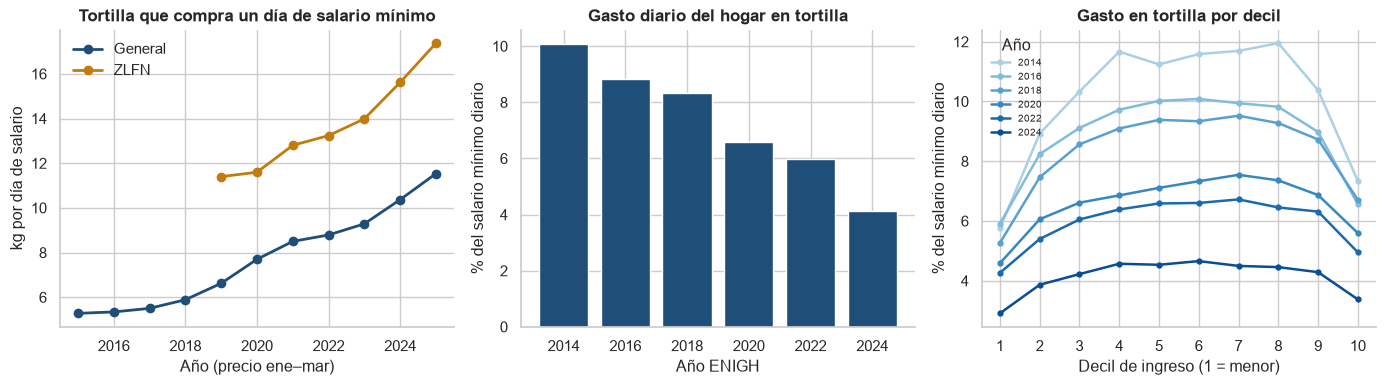

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
salario_general,66.45,73.04,80.04,88.36,102.68,123.22,141.70,172.87,207.44,248.93,278.80
precio_tortilleria,12.58,13.67,14.54,15.00,15.50,16.00,16.67,19.67,22.33,24.00,24.17
kg_por_dia_salario,5.28,5.34,5.50,5.89,6.62,7.70,8.50,8.79,9.29,10.37,11.54
minutos_trabajo_por_kg,90.90,89.81,87.20,81.48,72.46,62.33,56.46,54.61,51.68,46.28,41.61
kg_por_dia_salario_zlfn,NaN,NaN,NaN,NaN,11.40,11.60,12.80,13.24,13.99,15.62,17.37


anio,2014,2016,2018,2020,2022,2024
pct_salario,10.1,8.8,8.3,6.6,6.0,4.1


In [24]:
sal_q1 = sal[sal["fecha"].dt.month <= 3].groupby(["anio", "area"])["salario_minimo_diario_mxn"].mean().unstack()
poder = pd.DataFrame({
    "salario_general": sal_q1["general"],
    "precio_tortilleria": q1["tortilleria"],
}).dropna()
poder["kg_por_dia_salario"] = poder["salario_general"] / poder["precio_tortilleria"]
poder["minutos_trabajo_por_kg"] = poder["precio_tortilleria"] / poder["salario_general"] * 480
poder["kg_por_dia_salario_zlfn"] = sal_q1["zlfn"] / q1["tortilleria"]

sal_anual = sal.groupby(["anio", "area"])["salario_minimo_diario_mxn"].mean().unstack()["general"]
gasto = eni[eni["nivel"] == "nacional"].set_index("anio")["gasto_dia_hogar_mxn"]
peso = (gasto / sal_anual.reindex(gasto.index) * 100).rename("pct_salario")
gd = eni[eni["nivel"] == "decil"].assign(decil=lambda d: d["clave_nivel"].astype(int))
peso_dec = gd.assign(pct=lambda d: d["gasto_dia_hogar_mxn"] / d["anio"].map(sal_anual) * 100).pivot(index="decil", columns="anio", values="pct")

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(poder.index, poder["kg_por_dia_salario"], marker="o", color=AZUL, lw=2, label="General")
axs[0].plot(poder.index, poder["kg_por_dia_salario_zlfn"], marker="o", color=OCRE, lw=2, label="ZLFN")
axs[0].set_title("Tortilla que compra un día de salario mínimo"); axs[0].set_ylabel("kg por día de salario"); axs[0].set_xlabel("Año (precio ene–mar)")
axs[0].legend(frameon=False)
axs[1].bar(peso.index.astype(str), peso.values, color=AZUL)
axs[1].set_title("Gasto diario del hogar en tortilla"); axs[1].set_ylabel("% del salario mínimo diario"); axs[1].set_xlabel("Año ENIGH")
for c, anio in zip(paleta, peso_dec.columns):
    axs[2].plot(peso_dec.index, peso_dec[anio], marker="o", ms=3.5, color=c, lw=1.8, label=str(anio))
axs[2].set_title("Gasto en tortilla por decil"); axs[2].set_ylabel("% del salario mínimo diario"); axs[2].set_xlabel("Decil de ingreso (1 = menor)")
axs[2].set_xticks(range(1, 11)); axs[2].legend(title="Año", frameon=False, fontsize=7)
plt.tight_layout(); guardar(fig, "peso_salario"); plt.show()
display(poder.round(2).T)
display(peso.round(1).to_frame().T)

In [25]:
H.update(kgs15=poder.loc[2015, "kg_por_dia_salario"], kgs25=poder.loc[2025, "kg_por_dia_salario"],
         min15=poder.loc[2015, "minutos_trabajo_por_kg"], min25=poder.loc[2025, "minutos_trabajo_por_kg"],
         kgs_x=poder.loc[2025, "kg_por_dia_salario"] / poder.loc[2015, "kg_por_dia_salario"],
         sal_var=(poder.loc[2025, "salario_general"] / poder.loc[2015, "salario_general"] - 1) * 100,
         kgs19=poder.loc[2019, "kg_por_dia_salario"], kgs_z25=poder.loc[2025, "kg_por_dia_salario_zlfn"],
         pes14=peso.loc[2014], pes24=peso.loc[2024], pes_max=peso.max(), pes_max_anio=int(peso.idxmax()),
         pd1_14=peso_dec.loc[1, 2014], pd1_24=peso_dec.loc[1, 2024], pd10_24=peso_dec.loc[10, 2024])
display(Markdown(
    f"- Un día de salario mínimo general compraba **{H['kgs15']:.1f} kg** en 2015 y compra **{H['kgs25']:.1f} kg** en 2025 "
    f"({H['kgs_x']:.1f} veces; ZLFN: {H['kgs_z25']:.1f} kg). El tiempo de trabajo por kg pasó de {H['min15']:.0f} a {H['min25']:.0f} minutos de una jornada de 8 horas.\n"
    f"- El gasto diario promedio de los hogares en tortilla equivale a **{H['pes14']:.1f} %** del salario mínimo diario en 2014 y **{H['pes24']:.1f} %** en 2024.\n"
    f"- En el decil 1 pasa de {H['pd1_14']:.1f} % a {H['pd1_24']:.1f} %; en el decil 10 es {H['pd10_24']:.1f} % en 2024."
))

- Un día de salario mínimo general compraba **5.3 kg** en 2015 y compra **11.5 kg** en 2025 (2.2 veces; ZLFN: 17.4 kg). El tiempo de trabajo por kg pasó de 91 a 42 minutos de una jornada de 8 horas.
- El gasto diario promedio de los hogares en tortilla equivale a **10.1 %** del salario mínimo diario en 2014 y **4.1 %** en 2024.
- En el decil 1 pasa de 5.8 % a 2.9 %; en el decil 10 es 3.4 % en 2024.

## 8 | Síntesis

In [26]:
display(Markdown(f'''
1. **El salario mínimo se multiplicó por {H['g_factor']:.1f}** entre 2013 y 2025 ({H['g13']:.2f} a {H['g25']:.2f} MXN/día), con la mayor parte del avance desde 2019 ({H['g_cre_med_20_25']:.1f} % anual promedio en 2020–2025). La ventaja de la ZLFN sobre el general bajó de {H['brecha19']:.0f} % a {H['brecha25']:.0f} %.
2. **La tortilla subió menos que el salario:** el precio en tortillería pasó de {H['t15']:.2f} a {H['t25']:.2f} MXN/kg (+{H['t_var']:.0f} %, promedio ene–mar 2015–2025), frente a +{H['sal_var']:.0f} % del salario general en el mismo lapso. Un día de salario mínimo compra {H['kgs25']:.1f} kg en 2025, contra {H['kgs15']:.1f} kg en 2015.
3. **Brecha entre estados:** en 2025 el precio va de {H['p_barato']:.1f} MXN/kg ({H['barato']}) a {H['p_caro']:.1f} ({H['caro']}); el autoservicio es entre {H['razon_min']*100:.0f} y {H['razon_max']*100:.0f} % del precio de la tortillería.
4. **El consumo cayó:** por hogar de {H['kg14']:.3f} a {H['kg24']:.3f} kg/día ({H['kg_var']:+.0f} %) entre 2014 y 2024; per cápita, de {H['pc14']:.3f} a {H['pc24']:.3f} ({H['pc_var']:+.0f} %), porque los hogares son más pequeños. Bajó en {H['ent_cae']} de {H['ent_n']} entidades y en {int((var_dec<0).sum())} de 10 deciles.
5. **El gasto en tortilla pesa menos en el salario:** equivale a {H['pes14']:.1f} % del salario mínimo diario en 2014 y {H['pes24']:.1f} % en 2024. En el decil 1, de {H['pd1_14']:.1f} % a {H['pd1_24']:.1f} %.
6. **Los precios individuales son confiables y los saltos estatales engañan:** se marcó {H['pct_marc']:.1f} % de los registros, pero solo {H['n_error']:,} parecen capturas erróneas; el resto son establecimientos que cobran de forma consistente distinto. De {H['n_g10']} saltos mensuales de 10 % o más en la mediana estatal, solo {H['n_g10_resp']} están respaldados por la mitad de los establecimientos comunes.
7. **Las fuentes concuerdan en tendencia, no en nivel:** el precio implícito ENIGH difiere de PROFECO entre {H['dif_ult_min']:+.0f} % y {H['dif_ult_max']:+.0f} % (correlación de niveles {H['corr_nac']:.2f}); la cobertura parcial de PROFECO ({H['meses_min']}–{H['meses_max']} meses por año) limita comparar años completos.
'''))


1. **El salario mínimo se multiplicó por 4.5** entre 2013 y 2025 (61.38 a 278.80 MXN/día), con la mayor parte del avance desde 2019 (18.2 % anual promedio en 2020–2025). La ventaja de la ZLFN sobre el general bajó de 72 % a 51 %.
2. **La tortilla subió menos que el salario:** el precio en tortillería pasó de 12.58 a 24.17 MXN/kg (+92 %, promedio ene–mar 2015–2025), frente a +320 % del salario general en el mismo lapso. Un día de salario mínimo compra 11.5 kg en 2025, contra 5.3 kg en 2015.
3. **Brecha entre estados:** en 2025 el precio va de 18.0 MXN/kg (Puebla) a 32.0 (Sonora); el autoservicio es entre 56 y 79 % del precio de la tortillería.
4. **El consumo cayó:** por hogar de 0.543 a 0.455 kg/día (-16 %) entre 2014 y 2024; per cápita, de 0.143 a 0.136 (-6 %), porque los hogares son más pequeños. Bajó en 30 de 32 entidades y en 9 de 10 deciles.
5. **El gasto en tortilla pesa menos en el salario:** equivale a 10.1 % del salario mínimo diario en 2014 y 4.1 % en 2024. En el decil 1, de 5.8 % a 2.9 %.
6. **Los precios individuales son confiables y los saltos estatales engañan:** se marcó 8.1 % de los registros, pero solo 150 parecen capturas erróneas; el resto son establecimientos que cobran de forma consistente distinto. De 26 saltos mensuales de 10 % o más en la mediana estatal, solo 9 están respaldados por la mitad de los establecimientos comunes.
7. **Las fuentes concuerdan en tendencia, no en nivel:** el precio implícito ENIGH difiere de PROFECO entre -10 % y +6 % (correlación de niveles 0.97); la cobertura parcial de PROFECO (3–10 meses por año) limita comparar años completos.


**Limitaciones.** Precios y salarios son nominales. PROFECO cubre solo los primeros meses de cada año, y ENIGH es bienal y levantada en el segundo semestre. El consumo es compra monetaria, sin autoconsumo ni regalos.